# Experiment 001 – Baseline gradient-boosted trees

| | |
|---|---|
| **Task** | Task 1 – anti-cheat pre-filter, target `is_cheater` |
| **Metric** | F2 = 5·P·R / (4P + R) – recall counts 4× more than precision |
| **Question** | How well do LightGBM, XGBoost, and CatBoost do with **default settings** on the raw 31 features? |
| **Reference** | Scikit-learn `HistGradientBoostingClassifier` (default settings) |
| **Out of scope** | Feature engineering, imputation choices, hyperparameter tuning, ensembling – later experiments |

Facts about the data that shape this setup:

- 90,816 rows have a label (35% cheaters). 13,184 train rows have no label – they are left out here.
- ~98% of rows have at least one NaN. All four models handle NaN natively, so there is no imputation.
- A model that flags every player scores F2 ≈ 0.729. That is the floor.
- The best threshold for F2 is far below 0.5, so every score here uses a **tuned threshold**.

Protocol: 5-fold `StratifiedKFold` (seed 42). Every model sees the same folds and produces out-of-fold (OOF)
probabilities. All comparisons use OOF predictions only. The test set is not used in this experiment.

## 0. Setup

Imports.

In [1]:
import time
from pathlib import Path

import catboost as cb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, fbeta_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold

Paths and constants. The task root is the nearest folder with `pyproject.toml`, so the notebook runs
from any working directory. Outputs of this experiment go to their own folders.

In [2]:
EXPERIMENT = "001"
TASK_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = TASK_DIR / "data"
ASSETS_DIR = TASK_DIR / "assets" / "experiments" / EXPERIMENT
PRED_DIR = TASK_DIR / "predictions" / "experiments" / EXPERIMENT
ASSETS_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "is_cheater"
ID_COL = "player_id"
SEED = 42
N_FOLDS = 5

Plot style: one fixed color per model, the same in every chart.

In [3]:
MODEL_COLORS = {"HistGB": "#2a78d6", "LightGBM": "#eb6834", "XGBoost": "#1baf7a", "CatBoost": "#6250d6"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e6e6e6",
    "axes.titleweight": "bold",
})
pd.set_option("display.float_format", "{:.4f}".format)

Helper: save report figures as PNG, 300 dpi, tight box.

In [4]:
def save_fig(fig, name):
    path = ASSETS_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"saved {path.relative_to(TASK_DIR)}")

## 1. Data

Load train and keep only labeled rows.

In [5]:
train = pd.read_csv(DATA_DIR / "train.csv")
FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]

lab = train.dropna(subset=[TARGET]).reset_index(drop=True)
X = lab[FEATURES]
y = lab[TARGET].astype(int).to_numpy()
print(f"labeled rows: {len(lab):,}   features: {len(FEATURES)}   cheater rate: {y.mean():.3f}")

labeled rows: 90,816   features: 31   cheater rate: 0.349


Fixed folds. Each row gets one fold id; every model below uses the same split.

In [6]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_id = np.empty(len(y), dtype=int)
for k, (_, val_idx) in enumerate(skf.split(X, y)):
    fold_id[val_idx] = k
pd.crosstab(fold_id, y, margins=True).rename_axis(index="fold", columns="is_cheater")

is_cheater,0,1,All
fold,,,
0,11819,6345,18164
1,11818,6345,18163
2,11818,6345,18163
3,11818,6345,18163
4,11818,6345,18163
All,59091,31725,90816


## 2. Metric helpers

`best_threshold` scans every distinct OOF probability (via the precision-recall curve) and returns the
threshold with the highest F2.

In [7]:
def f2_curve(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    precision, recall = precision[:-1], recall[:-1]
    f2 = 5 * precision * recall / np.clip(4 * precision + recall, 1e-12, None)
    return thresholds, f2, precision, recall


def best_threshold(y_true, proba):
    thresholds, f2, _, _ = f2_curve(y_true, proba)
    i = np.argmax(f2)
    return thresholds[i], f2[i]

Choosing the threshold on the same OOF predictions that we then score is slightly optimistic.
`nested_f2` gives an honest estimate: for each fold, pick the threshold on the **other four** folds'
OOF predictions, then score the held-out fold with it. Rows from all folds are pooled for one F2.

In [8]:
def nested_f2(y_true, proba, folds):
    pred = np.zeros_like(y_true)
    for k in np.unique(folds):
        inside = folds != k
        t, _ = best_threshold(y_true[inside], proba[inside])
        pred[~inside] = proba[~inside] >= t
    return fbeta_score(y_true, pred, beta=2)

## 3. Cross-validation runner

`run_cv` fits one fresh model per fold and returns the OOF probabilities plus the fit time.
The model is built by a factory function so no state leaks between folds.

In [9]:
def run_cv(name, make_model):
    oof = np.zeros(len(y))
    start = time.perf_counter()
    for k in range(N_FOLDS):
        trn, val = fold_id != k, fold_id == k
        model = make_model()
        model.fit(X[trn], y[trn])
        oof[val] = model.predict_proba(X[val])[:, 1]
        print(f"  fold {k}: ROC AUC {roc_auc_score(y[val], oof[val]):.4f}")
    seconds = time.perf_counter() - start
    print(f"{name}: OOF ROC AUC {roc_auc_score(y, oof):.4f}  ({seconds:.0f}s)")
    return oof, seconds


oof_preds, fit_seconds = {}, {}

## 4. Models (default settings)

Reference model: scikit-learn `HistGradientBoostingClassifier`.

In [10]:
oof_preds["HistGB"], fit_seconds["HistGB"] = run_cv(
    "HistGB", lambda: HistGradientBoostingClassifier(random_state=SEED)
)

  fold 0: ROC AUC 0.8896


  fold 1: ROC AUC 0.8908


  fold 2: ROC AUC 0.8913


  fold 3: ROC AUC 0.8857


  fold 4: ROC AUC 0.8919
HistGB: OOF ROC AUC 0.8898  (6s)


LightGBM. `verbose=-1` only silences the training log.

In [11]:
oof_preds["LightGBM"], fit_seconds["LightGBM"] = run_cv(
    "LightGBM", lambda: lgb.LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1)
)

  fold 0: ROC AUC 0.8904


  fold 1: ROC AUC 0.8913


  fold 2: ROC AUC 0.8906


  fold 3: ROC AUC 0.8870


  fold 4: ROC AUC 0.8933
LightGBM: OOF ROC AUC 0.8905  (5s)


XGBoost with the fast `hist` tree method (the default in XGBoost ≥ 2).

In [12]:
oof_preds["XGBoost"], fit_seconds["XGBoost"] = run_cv(
    "XGBoost", lambda: xgb.XGBClassifier(random_state=SEED, n_jobs=-1, tree_method="hist")
)

  fold 0: ROC AUC 0.8862


  fold 1: ROC AUC 0.8853


  fold 2: ROC AUC 0.8865


  fold 3: ROC AUC 0.8824


  fold 4: ROC AUC 0.8888
XGBoost: OOF ROC AUC 0.8858  (5s)


CatBoost. Default is 1000 trees with an automatic learning rate, so it is the slowest. `allow_writing_files=False` stops it from writing a `catboost_info/` log folder.

In [13]:
oof_preds["CatBoost"], fit_seconds["CatBoost"] = run_cv(
    "CatBoost", lambda: cb.CatBoostClassifier(random_seed=SEED, verbose=0, thread_count=-1, allow_writing_files=False)
)

  fold 0: ROC AUC 0.8877


  fold 1: ROC AUC 0.8887


  fold 2: ROC AUC 0.8899


  fold 3: ROC AUC 0.8842


  fold 4: ROC AUC 0.8902
CatBoost: OOF ROC AUC 0.8881  (90s)


## 5. Results

One row per model, all on OOF predictions:

- `roc_auc`, `pr_auc` – ranking quality, threshold-free.
- `best_f2`, `threshold` – F2 at the threshold tuned on all OOF rows (optimistic).
- `nested_f2` – F2 with the threshold tuned on other folds (honest; use this to compare).
- `f2_at_0.5` – what the default threshold would give.

In [14]:
rows = []
for name, proba in oof_preds.items():
    t, f2 = best_threshold(y, proba)
    rows.append({
        "model": name,
        "roc_auc": roc_auc_score(y, proba),
        "pr_auc": average_precision_score(y, proba),
        "best_f2": f2,
        "threshold": t,
        "nested_f2": nested_f2(y, proba, fold_id),
        "f2_at_0.5": fbeta_score(y, proba >= 0.5, beta=2),
        "fit_seconds": fit_seconds[name],
    })
results = pd.DataFrame(rows).set_index("model").sort_values("nested_f2", ascending=False)
results.to_csv(ASSETS_DIR / "results.csv")
results

,roc_auc,pr_auc,best_f2,threshold,nested_f2,f2_at_0.5,fit_seconds
model,,,,,,,
LightGBM,0.8905,0.8315,0.8367,0.1948,0.8364,0.6197,4.6704
HistGB,0.8898,0.8306,0.8367,0.1856,0.8361,0.6191,5.6655
CatBoost,0.8881,0.8277,0.8359,0.1651,0.8356,0.6337,89.5583
XGBoost,0.8858,0.8252,0.8343,0.1520,0.8340,0.6332,5.1156


Fold-to-fold stability: F2 per fold at that fold's own best threshold. A small spread means
the difference between models is real, not noise from one split.

In [15]:
per_fold = pd.DataFrame({
    name: [best_threshold(y[fold_id == k], proba[fold_id == k])[1] for k in range(N_FOLDS)]
    for name, proba in oof_preds.items()
}).rename_axis("fold")
per_fold.loc["mean"] = per_fold.mean()
per_fold.loc["std"] = per_fold.iloc[:N_FOLDS].std()
per_fold

,HistGB,LightGBM,XGBoost,CatBoost
fold,,,,
0,0.8374,0.8364,0.8343,0.8359
1,0.8388,0.8373,0.8358,0.8358
2,0.8374,0.8388,0.8352,0.8366
3,0.8366,0.8355,0.8332,0.8343
4,0.8370,0.8387,0.8362,0.8387
mean,0.8374,0.8374,0.8349,0.8363
std,0.0009,0.0014,0.0012,0.0016


F2 against the decision threshold for each model. The curve shape shows how sensitive F2 is to the threshold.

saved assets/experiments/001/f2-threshold-curves.png


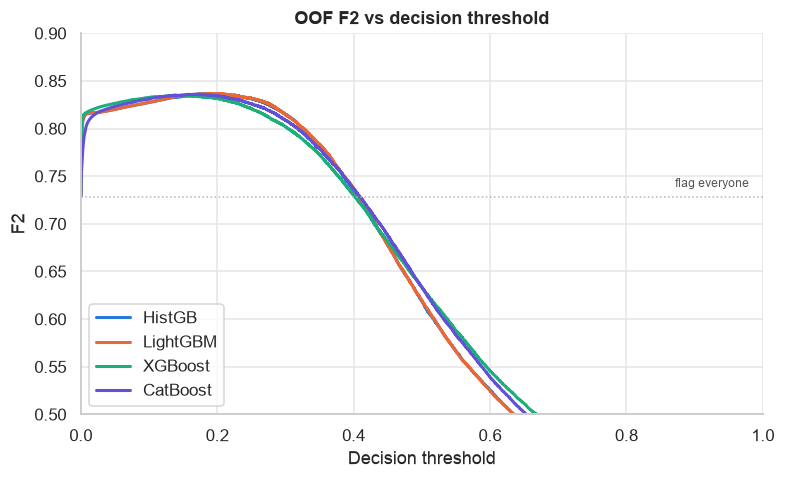

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, proba in oof_preds.items():
    thresholds, f2, _, _ = f2_curve(y, proba)
    ax.plot(thresholds, f2, color=MODEL_COLORS[name], linewidth=2, label=name)
ax.axhline(fbeta_score(y, np.ones_like(y), beta=2), color="#b5b4ae", linestyle=":", linewidth=1)
ax.text(0.98, fbeta_score(y, np.ones_like(y), beta=2) + 0.01, "flag everyone", ha="right", fontsize=8, color="#555")
ax.set(title="OOF F2 vs decision threshold", xlabel="Decision threshold", ylabel="F2", xlim=(0, 1), ylim=(0.5, 0.9))
ax.legend(loc="lower left")
save_fig(fig, "f2-threshold-curves")
plt.show()

Zoom on the top of the curves, where the models differ.

saved assets/experiments/001/f2-threshold-zoom.png


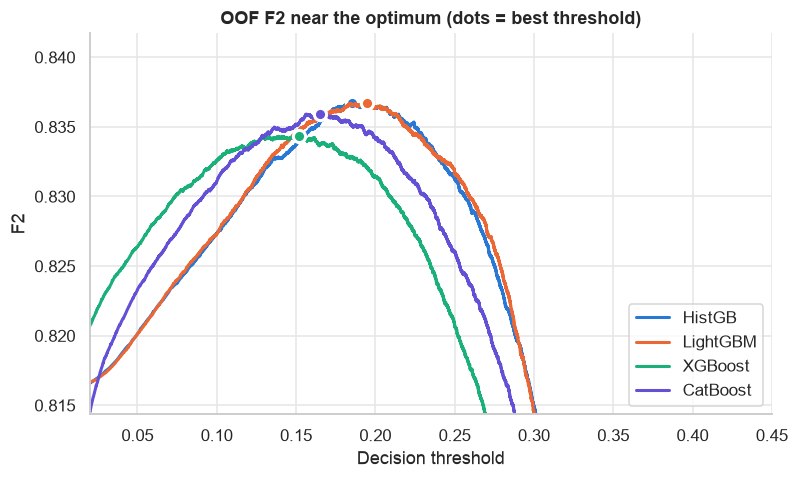

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, proba in oof_preds.items():
    thresholds, f2, _, _ = f2_curve(y, proba)
    ax.plot(thresholds, f2, color=MODEL_COLORS[name], linewidth=2, label=name)
    t, best = best_threshold(y, proba)
    ax.plot(t, best, "o", color=MODEL_COLORS[name], markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.set(title="OOF F2 near the optimum (dots = best threshold)", xlabel="Decision threshold", ylabel="F2",
       xlim=(0.02, 0.45), ylim=(results.best_f2.min() - 0.02, results.best_f2.max() + 0.005))
ax.legend(loc="lower right")
save_fig(fig, "f2-threshold-zoom")
plt.show()

Precision-recall curves. F2 rewards the high-recall end (right side).

saved assets/experiments/001/precision-recall-curves.png


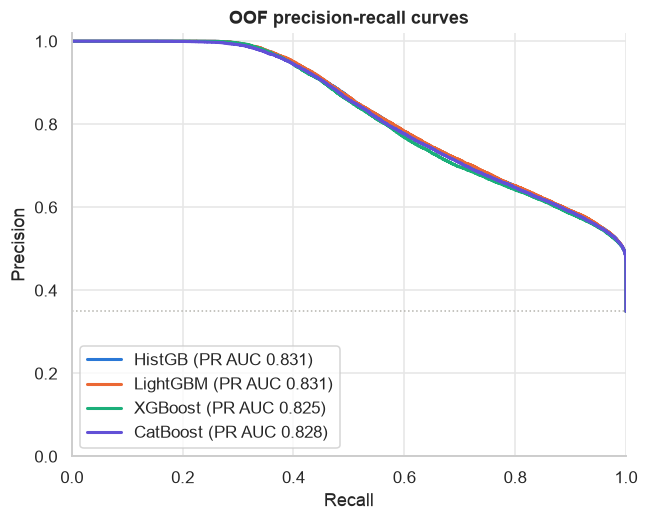

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, proba in oof_preds.items():
    _, _, precision, recall = f2_curve(y, proba)
    ax.plot(recall, precision, color=MODEL_COLORS[name], linewidth=2,
            label=f"{name} (PR AUC {average_precision_score(y, proba):.3f})")
ax.axhline(y.mean(), color="#b5b4ae", linestyle=":", linewidth=1)
ax.set(title="OOF precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
save_fig(fig, "precision-recall-curves")
plt.show()

How similar are the models' predictions? Low correlation between strong models means a blend
(a later experiment) can help.

In [19]:
oof_frame = pd.DataFrame(oof_preds)
oof_frame.corr(method="spearman")

,HistGB,LightGBM,XGBoost,CatBoost
HistGB,1.0000,0.9882,0.9671,0.9717
LightGBM,0.9882,1.0000,0.9679,0.9722
XGBoost,0.9671,0.9679,1.0000,0.9638
CatBoost,0.9717,0.9722,0.9638,1.0000


## 6. Save OOF predictions

Save OOF probabilities with the player id and fold id, so later experiments can compare or blend without re-training.

In [20]:
oof_out = pd.DataFrame({ID_COL: lab[ID_COL], "fold": fold_id, TARGET: y}).join(oof_frame.add_prefix("oof_"))
oof_out.to_csv(PRED_DIR / "oof.csv", index=False)
print(f"saved {(PRED_DIR / 'oof.csv').relative_to(TASK_DIR)}  {oof_out.shape}")

saved predictions/experiments/001/oof.csv  (90816, 7)


## 7. Submission (LightGBM)


Refit the best model, LightGBM, on **all** labeled train rows. Use the F2 threshold tuned on its OOF
predictions. The test set is used only for prediction here.


In [21]:

SUBMIT_MODEL = "LightGBM"
submit_threshold, submit_oof_f2 = best_threshold(y, oof_preds[SUBMIT_MODEL])
print(f"{SUBMIT_MODEL}: threshold {submit_threshold:.4f}  (OOF F2 {submit_oof_f2:.4f})")

final_model = lgb.LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1).fit(X, y)


LightGBM: threshold 0.1948  (OOF F2 0.8367)


Predict test probabilities and save them with the player id.

In [22]:

test = pd.read_csv(DATA_DIR / "test.csv")
assert list(test.columns) == [ID_COL, *FEATURES]
test_proba = final_model.predict_proba(test[FEATURES])[:, 1]

pd.DataFrame({ID_COL: test[ID_COL], "proba": test_proba}).to_csv(PRED_DIR / "test.csv", index=False)
print(f"saved {(PRED_DIR / 'test.csv').relative_to(TASK_DIR)}")


saved predictions/experiments/001/test.csv



Sanity check: the share of players flagged on test should be close to the share flagged on OOF
at the same threshold. A large gap would mean the probabilities shifted.


In [23]:

print(f"flagged on OOF : {(oof_preds[SUBMIT_MODEL] >= submit_threshold).mean():.3f}")
print(f"flagged on test: {(test_proba >= submit_threshold).mean():.3f}")


flagged on OOF : 0.638
flagged on test: 0.603



Write `submit/index.csv` (`id,task1`). The sample submission has no `player_id`; its ids
`ANS00001…ANS25889` follow the row order of `test.csv`, so row *i* of test maps to the *i*-th sample id.


In [24]:

sample = pd.read_csv(TASK_DIR.parent / "submission" / "sample_submission.csv", usecols=["id"])
assert len(sample) == len(test), "sample submission and test.csv differ in row count"

submit = pd.DataFrame({"id": sample["id"], "task1": (test_proba >= submit_threshold).astype(int)})
SUBMIT_PATH = TASK_DIR / "submit" / "index.csv"
submit.to_csv(SUBMIT_PATH, index=False)
print(f"saved {SUBMIT_PATH.relative_to(TASK_DIR)}  rows {len(submit):,}  share of 1s {submit.task1.mean():.3f}")
submit.head()


saved submit/index.csv  rows 25,889  share of 1s 0.603


,id,task1
0,ANS00001,1
1,ANS00002,1
2,ANS00003,1
3,ANS00004,1
4,ANS00005,0


## 8. Conclusion

| Model | OOF ROC AUC | Nested F2 | Best threshold | Fit time (5 folds) |
|---|---|---|---|---|
| LightGBM | 0.8905 | **0.8364** | 0.19 | 4 s |
| HistGB | 0.8898 | 0.8361 | 0.19 | 7 s |
| CatBoost | 0.8881 | 0.8356 | 0.17 | 43 s |
| XGBoost | 0.8858 | 0.8340 | 0.15 | 3 s |

**Findings**

- All four default GBDTs land at nested F2 ≈ 0.834–0.836. The gap between the best and the worst
  (0.0024) is only about 2× the fold-to-fold standard deviation (≈ 0.001–0.0016), so no model is clearly better.
- The nested F2 is only ~0.0003 below the optimistic best F2 – the tuned threshold is stable across folds.
- The F2-optimal threshold sits at 0.15–0.19 (recall ≈ 0.98). The default 0.5 threshold loses ~0.20 F2.
- OOF predictions are highly correlated (Spearman 0.96–0.99), so a plain blend of these defaults
  will add little. Diversity has to come from features or different settings.
- Every model reaches about the same ceiling, which suggests the limit is in the **data and features**,
  not the choice of algorithm.

**Decision for the next experiment**

- Use **LightGBM** as the main model: best nested F2 and fast enough for many CV runs and Optuna.
- Keep the same folds (`StratifiedKFold`, 5 splits, seed 42) and the same metrics (nested F2 to compare).
- Next experiment (002): feature work on top of LightGBM – count of class-only range hits, account-maturity
  ratios (`friend_network_size / account_age_days`, reports per day of account age), and dropping
  zero-importance features. Then tune with Optuna (003) and blend (004).

**Submission:** LightGBM refit on all labeled rows, threshold from its OOF F2 → `submit/index.csv`.

Outputs: `assets/experiments/001/` (results table and curves), `predictions/experiments/001/oof.csv` and `test.csv`, `submit/index.csv`.